This project pertains to supply chain management domain. In this project we will analyse the supply cost of company in shipping products across Brasil
we will analyse from where we are bleeding the most revenue and try to mitigate it using some steps.

In [4]:
#!pip install "pulp[cbc]"

In [5]:
from pathlib import Path
import pandas as pd

folder = Path(r"D:\Supplychain")  # change this

dfs = {
    file.stem: pd.read_csv(file)
    for file in folder.glob("*.csv")
}


In [6]:
print(dfs.keys())

dict_keys(['olist_customers_dataset', 'olist_geolocation_dataset', 'olist_orders_dataset', 'olist_order_items_dataset', 'olist_order_payments_dataset', 'olist_order_reviews_dataset', 'olist_products_dataset', 'olist_sellers_dataset', 'product_category_name_translation'])


In [7]:
customers    = dfs['olist_customers_dataset']
geo          = dfs['olist_geolocation_dataset']
orders       = dfs['olist_orders_dataset']
order_items  = dfs['olist_order_items_dataset']
payments     = dfs['olist_order_payments_dataset']
reviews      = dfs['olist_order_reviews_dataset']
products     = dfs['olist_products_dataset']
sellers      = dfs['olist_sellers_dataset']
categories   = dfs['product_category_name_translation']

In [8]:
for name, df in {
    'customers': customers,
    'geo': geo,
    'orders': orders,
    'order_items': order_items,
    'payments': payments,
    'reviews': reviews,
    'products': products,
    'sellers': sellers,
    'categories': categories
}.items():
    print(f"\n{name.upper()}")
    print(df.columns.tolist())


CUSTOMERS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

GEO
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

ORDERS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ORDER_ITEMS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

PAYMENTS
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

REVIEWS
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

PRODUCTS
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_widt

In [9]:


# Assuming you have loaded products_df and categories_df
products= products.merge(categories, on='product_category_name', how='left')

# Drop the Portuguese column and rename the English one to keep the schema clean
products.drop('product_category_name', axis=1, inplace=True)
products.rename(columns={'product_category_name_english': 'product_category_name'}, inplace=True)

In [10]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [11]:
geo.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


we are merging 'customers' and 'geo' but see in 'geo' the column 'geolocation_zip_code_prefix' contains all the zip codes and corresponding to 
each code we have more than one cordinate(lat,long) so if we directly meerge say in 'customers' there are say 'n' zip codes and for each single zipcode in 'geo' has some k(i) coordinates so number of rows will be k(i)*n, hence first we will aggregate such that we will take one coordinate for one zip code.

In [12]:
# 1. Aggregate the GEO table to ensure one coordinate per zip code
geo_agg = geo.groupby('geolocation_zip_code_prefix').agg({
    'geolocation_lat': 'mean',
    'geolocation_lng': 'mean'
}).reset_index()

# 2. Merge the aggregated coordinates into the SELLERS table
sellers = sellers.merge(
    geo_agg, 
    left_on='seller_zip_code_prefix', 
    right_on='geolocation_zip_code_prefix', 
    how='left'
)

# 3. Drop the redundant connecting column
sellers.drop('geolocation_zip_code_prefix', axis=1, inplace=True)

In [13]:
# Rename in the customers table
customers.rename(columns={'customer_id': 'transaction_id'}, inplace=True)

# Rename in the orders table to maintain the matching key
orders.rename(columns={'customer_id': 'transaction_id'}, inplace=True)

In [14]:
orders.head()

,order_id,transaction_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [15]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


We first merged 'order' and 'order_items' now see the columns of both dataframe
ORDERS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ORDER_ITEMS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

we are merging to make logistics_master ok here from 'orders' order_id is picked and then its matched with order_id in 'order_items' if both matches successfully we keep it oterwise the row is discarded. same procedure is followed when we merged it with customers we mapped it on transaction_id.


In [16]:
# 1. Merge Orders and Order Items
logistics_master = orders.merge(order_items, on='order_id', how='inner')

# 2. Merge with Customers using our renamed key
logistics_master = logistics_master.merge(
    customers, 
    on='transaction_id', 
    how='inner'
)

In [17]:
logistics_master = logistics_master.merge(
    payments, 
    on='order_id', 
    how='inner'
)

In [18]:
logistics_master = logistics_master.merge(
    products, 
    on='product_id', 
    how='inner'
)

In [19]:
logistics_master = logistics_master.merge(
    sellers, 
    on='seller_id', 
    how='inner'
)

In [20]:
logistics_master.shape

(117601, 35)

In [21]:
logistics_master.columns

Index(['order_id', 'transaction_id', 'order_status',
       'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'order_item_id', 'product_id',
       'seller_id', 'shipping_limit_date', 'price', 'freight_value',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'product_category_name', 'seller_zip_code_prefix', 'seller_city',
       'seller_state', 'geolocation_lat', 'geolocation_lng'],
      dtype='object')

In [22]:
# Drop the e-commerce marketing columns
fluff_columns = [
    'product_name_lenght', 
    'product_description_lenght', 
    'product_photos_qty', 
    
]

logistics_master.drop(columns=fluff_columns, inplace=True)

# Verify the final, lean logistics matrix
print(logistics_master.columns)

Index(['order_id', 'transaction_id', 'order_status',
       'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'order_item_id', 'product_id',
       'seller_id', 'shipping_limit_date', 'price', 'freight_value',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'product_category_name', 'seller_zip_code_prefix', 'seller_city',
       'seller_state', 'geolocation_lat', 'geolocation_lng'],
      dtype='object')


In [23]:
dfm = logistics_master

In [24]:
dfm.shape

(117601, 32)

In [25]:
# Drop phantom boxes caused by multi-payment orders
logistics_master.drop_duplicates(subset=['order_id', 'order_item_id'], keep='first', inplace=True)

# Verify we are back to our true physical count
print(logistics_master.shape)

(112647, 32)


In [26]:
dfm.dtypes

order_id                          object
transaction_id                    object
order_status                      object
order_purchase_timestamp          object
order_approved_at                 object
order_delivered_carrier_date      object
order_delivered_customer_date     object
order_estimated_delivery_date     object
order_item_id                      int64
product_id                        object
seller_id                         object
shipping_limit_date               object
price                            float64
freight_value                    float64
customer_unique_id                object
customer_zip_code_prefix           int64
customer_city                     object
customer_state                    object
payment_sequential                 int64
payment_type                      object
payment_installments               int64
payment_value                    float64
product_weight_g                 float64
product_length_cm                float64
product_height_c

In [27]:

pd.set_option('display.max_columns', None)

dfm.head()

,order_id,transaction_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,payment_sequential,payment_type,payment_installments,payment_value,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name,seller_zip_code_prefix,seller_city,seller_state,geolocation_lat,geolocation_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1,credit_card,1,18.12,500.0,19.0,8.0,13.0,housewares,9350,maua,SP,-23.680729,-46.444238
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1,boleto,1,141.46,400.0,19.0,13.0,19.0,perfumery,31570,belo horizonte,SP,-19.807681,-43.980427
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1,credit_card,3,179.12,420.0,24.0,19.0,21.0,auto,14840,guariba,SP,-21.363502,-48.229601
5,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1,credit_card,1,72.20,450.0,30.0,10.0,20.0,pet_shop,31842,belo horizonte,MG,-19.837682,-43.924053
6,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1,credit_card,1,28.62,250.0,51.0,15.0,15.0,stationery,8752,mogi das cruzes,SP,-23.543395,-46.262086


In [28]:
dfm.info()

<class 'pandas.core.frame.DataFrame'>
Index: 112647 entries, 0 to 117600
Data columns (total 32 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       112647 non-null  object 
 1   transaction_id                 112647 non-null  object 
 2   order_status                   112647 non-null  object 
 3   order_purchase_timestamp       112647 non-null  object 
 4   order_approved_at              112632 non-null  object 
 5   order_delivered_carrier_date   111453 non-null  object 
 6   order_delivered_customer_date  110193 non-null  object 
 7   order_estimated_delivery_date  112647 non-null  object 
 8   order_item_id                  112647 non-null  int64  
 9   product_id                     112647 non-null  object 
 10  seller_id                      112647 non-null  object 
 11  shipping_limit_date            112647 non-null  object 
 12  price                          1126

In [29]:
dfm = dfm.dropna(subset=['order_approved_at','product_weight_g','product_length_cm','product_height_cm','product_width_cm'])

In [30]:
# 1. Clear any ambiguous coordinates
dfm.drop(columns=['geolocation_lat', 'geolocation_lng'], errors='ignore', inplace=True)

# 2. Map the Seller coordinates
dfm = dfm.merge(
    geo_agg, 
    left_on='seller_zip_code_prefix', 
    right_on='geolocation_zip_code_prefix', 
    how='inner'
)
dfm.rename(columns={'geolocation_lat': 'seller_lat', 'geolocation_lng': 'seller_lng'}, inplace=True)
dfm.drop(columns=['geolocation_zip_code_prefix'], inplace=True)

# 3. Map the Customer coordinates
dfm = dfm.merge(
    geo_agg, 
    left_on='customer_zip_code_prefix', 
    right_on='geolocation_zip_code_prefix', 
    how='inner'
)
dfm.rename(columns={'geolocation_lat': 'customer_lat', 'geolocation_lng': 'customer_lng'}, inplace=True)
dfm.drop(columns=['geolocation_zip_code_prefix'],errors = 'ignore', inplace=True)

C:\Users\HP\AppData\Local\Temp\ipykernel_9348\1792474123.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfm.drop(columns=['geolocation_lat', 'geolocation_lng'], errors='ignore', inplace=True)


In [31]:
# Convert to datetime (invalid parsing will be set as NaT - Not a Time)
time_cols = ['order_purchase_timestamp', 'order_estimated_delivery_date', 
             'order_delivered_carrier_date', 'order_delivered_customer_date']

for col in time_cols:
    dfm[col] = pd.to_datetime(dfm[col], errors='coerce')

In [32]:
dfm.isna().sum()

order_id                            0
transaction_id                      0
order_status                        0
order_purchase_timestamp            0
order_approved_at                   0
order_delivered_carrier_date     1183
order_delivered_customer_date    2436
order_estimated_delivery_date       0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
payment_sequential                  0
payment_type                        0
payment_installments                0
payment_value                       0
product_weight_g                    0
product_length_cm                   0
product_height_cm                   0
product_width_cm                    0
product_cate

In [33]:
dfm[['price','freight_value','payment_installments','payment_value']].describe()

,price,freight_value,payment_installments,payment_value
count,112060.000000,112060.000000,112060.000000,112060.000000
mean,120.682704,19.984227,3.002213,177.598328
std,183.776605,15.821785,2.796171,271.203290
min,0.850000,0.000000,0.000000,0.010000
25%,39.900000,13.070000,1.000000,64.027500
50%,74.985000,16.250000,2.000000,112.490000
75%,134.900000,21.150000,4.000000,193.500000
max,6735.000000,409.680000,24.000000,13664.080000


In [34]:
dfm[['product_weight_g','product_length_cm','product_height_cm','product_width_cm']].describe()

,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,112060.000000,112060.000000,112060.000000,112060.000000
mean,2092.175129,30.145627,16.613573,22.986730
std,3746.702821,16.145551,13.453976,11.682021
min,0.000000,7.000000,2.000000,6.000000
25%,300.000000,18.000000,8.000000,15.000000
50%,700.000000,25.000000,13.000000,20.000000
75%,1800.000000,38.000000,20.000000,30.000000
max,40425.000000,105.000000,105.000000,118.000000


in transportation 'o' gm weight doesn't make any sense 

In [35]:
# Apply a 100g minimum billable weight to any zero-weight shipments
dfm.loc[dfm['product_weight_g'] == 0, 'product_weight_g'] = 100

# Verify the floor is now set
print(dfm['product_weight_g'].describe())

count    112060.000000
mean       2092.182268
std        3746.698930
min           2.000000
25%         300.000000
50%         700.000000
75%        1800.000000
max       40425.000000
Name: product_weight_g, dtype: float64


## Phase 2: Exploratory Data Analysis (EDA) - Spatial Demand Distribution

Before feeding 112,000+ geographic coordinates into an optimization solver, we must validate the business necessity of spatial clustering. 

In this section, we aggregate the network's demand into two critical constraints:
1. **Physical Volume (Metric Tons):** Dictates truck capacity and warehouse sizing.
2. **Financial Value (Millions R$):** Dictates value density, insurance, and margin analysis.

By visualizing the Top 15 logistics hubs alongside an interactive regional query tool, we can mathematically confirm a severe right-skew in the spatial distribution. Megacities like São Paulo command massive volume, while thousands of rural destinations form a "long tail" of low-density freight. 

This extreme geographic imbalance provides the architectural justification for our next step: using `MiniBatchKMeans` to consolidate these scattered delivery points into 50 highly balanced, regional Demand Nodes for the MILP solver.

In [36]:
dfm[['customer_city','seller_city']].nunique()

customer_city    4060
seller_city       611
dtype: int64

## Phase 3: Exploratory Data Analysis (EDA) - Temporal Trend & Capacity Planning

While spatial distribution dictates *where* our network facilities should be located, temporal demand dictates *how large* those facilities must be. Designing a logistics network based purely on "average" monthly volume guarantees systemic failure during peak retail seasons.

In this section, we track three core operational metrics over time:
1. **Order Volume:** Dictates warehouse throughput (picking, packing, and sortation labor).
2. **Physical Freight (Metric Tons):** Dictates required warehouse floor space and outbound truck capacity.
3. **Financial Value (Millions R$):** Tracks revenue flow and peak inventory holding risk.

By stacking these metrics into a monthly trend view, we can immediately identify extreme seasonal spikes (such as the Brazilian Black Friday surge in November). This temporal stress-testing ensures that when we set our maximum capacity constraints in the MILP solver, we are engineering a network built to survive maximum throughput, rather than just the statistical mean.

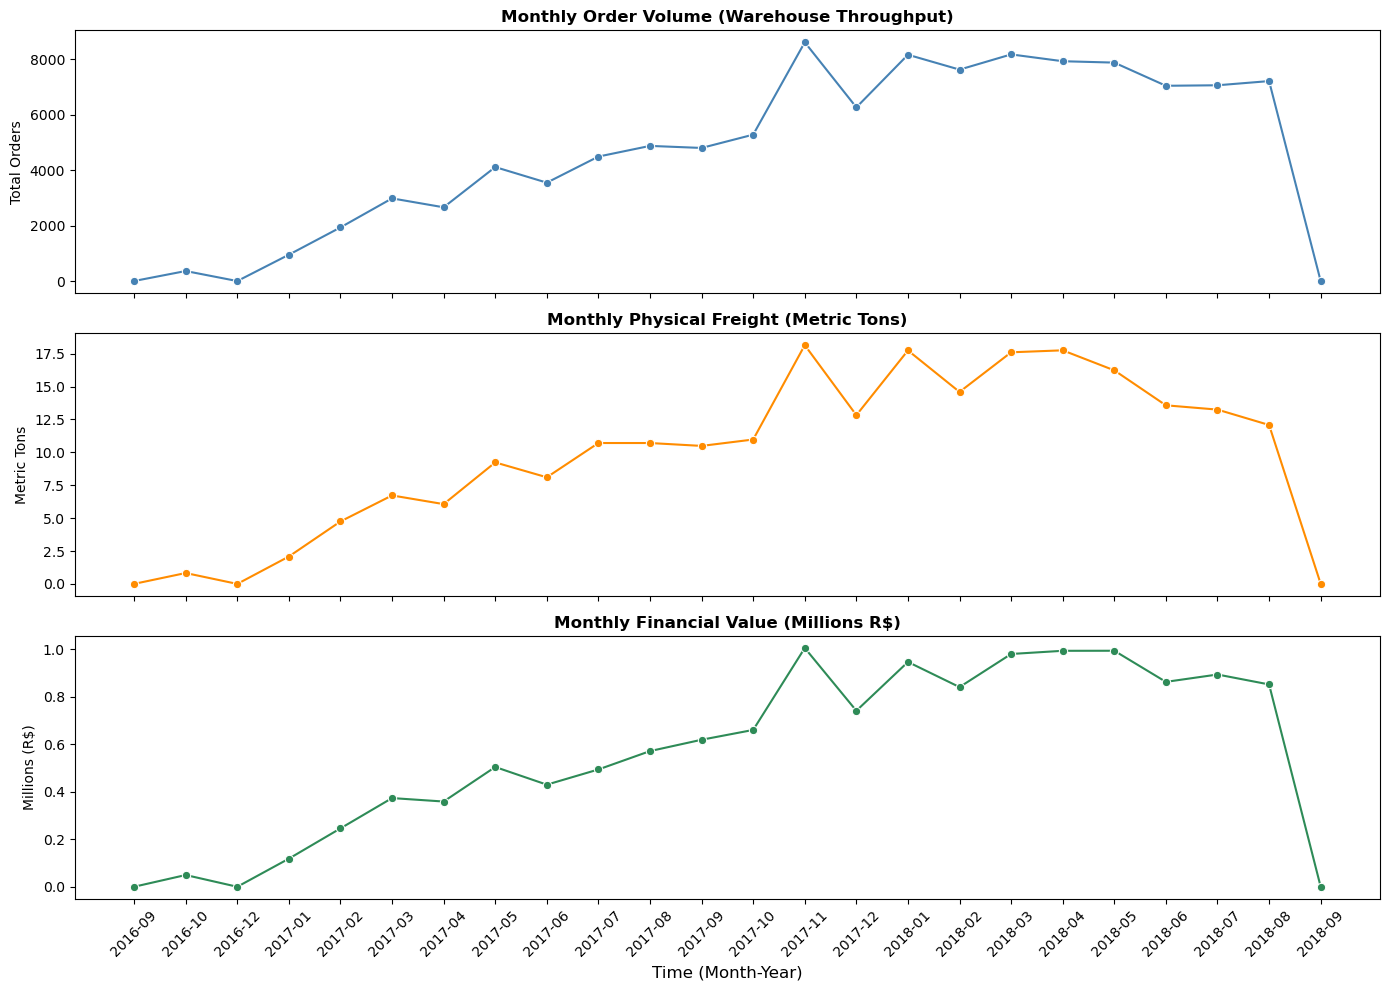

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Create a Year-Month column for clean time-series grouping
dfm['year_month'] = dfm['order_purchase_timestamp'].dt.to_period('M')

# 2. Aggregate the three core metrics by month
monthly_trend = dfm.groupby('year_month').agg(
    total_orders=('order_id', 'count'),
    total_weight_tons=('product_weight_g', lambda x: x.sum() / 1_000_000),
    total_revenue_millions=('price', lambda x: x.sum() / 1_000_000)
).reset_index()

# Convert the period to a string so Matplotlib can plot it cleanly
monthly_trend['year_month'] = monthly_trend['year_month'].astype(str)

# 3. Build a professional 3-panel vertical dashboard
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Panel 1: Order Volume (Operations throughput)
sns.lineplot(data=monthly_trend, x='year_month', y='total_orders', ax=axes[0], color='steelblue', marker='o')
axes[0].set_title('Monthly Order Volume (Warehouse Throughput)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Total Orders')

# Panel 2: Physical Weight (Truck & Freight Capacity)
sns.lineplot(data=monthly_trend, x='year_month', y='total_weight_tons', ax=axes[1], color='darkorange', marker='o')
axes[1].set_title('Monthly Physical Freight (Metric Tons)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Metric Tons')

# Panel 3: Financial Value (Revenue & Insured Risk)
sns.lineplot(data=monthly_trend, x='year_month', y='total_revenue_millions', ax=axes[2], color='seagreen', marker='o')
axes[2].set_title('Monthly Financial Value (Millions R$)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Millions (R$)')
axes[2].set_xlabel('Time (Month-Year)', fontsize=12)

# Format the X-axis for readability
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Steep drop in last it shows that month is incompelete so relevance is 2016-9 to 2018-8 ie 23 months

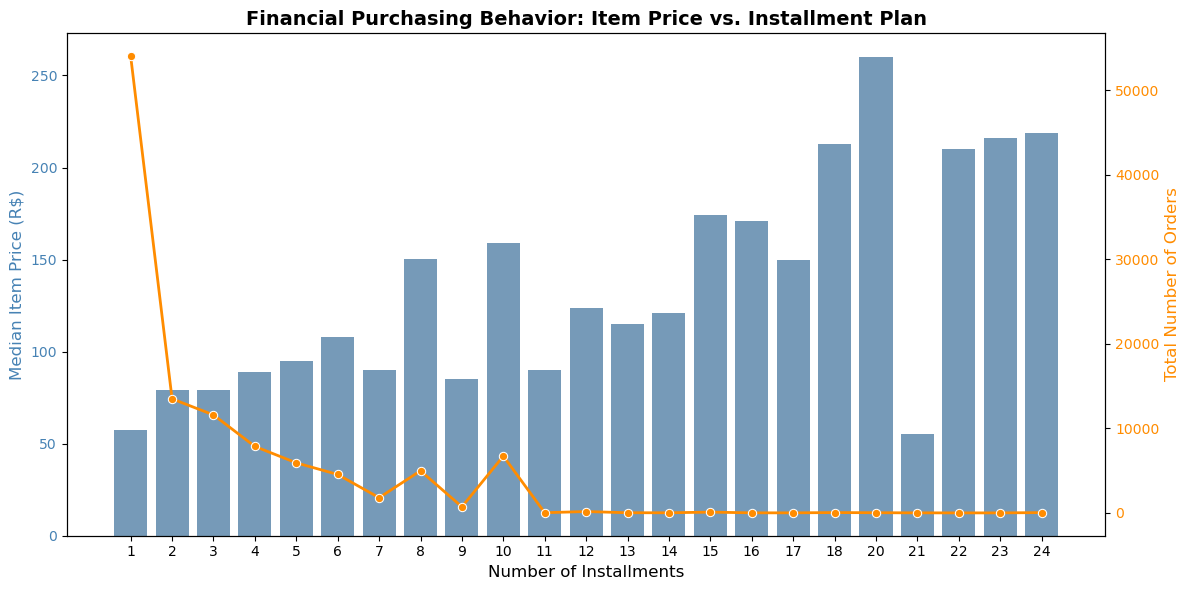

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter out zero-installment anomalies (often just systemic glitches or distinct payment types like points)
install_df = dfm[dfm['payment_installments'] > 0]

# 2. Calculate the median and max price for each installment count
installment_trends = install_df.groupby('payment_installments').agg(
    median_price=('price', 'median'),
    max_price=('price', 'max'),
    order_count=('order_id', 'count')
).reset_index()

# 3. Create a dual-axis plot to show both Median Price and Order Volume
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot 1: Median Price (Bar Chart)
sns.barplot(
    data=installment_trends, 
    x='payment_installments', 
    y='median_price', 
    color='steelblue', 
    alpha=0.8, 
    ax=ax1
)
ax1.set_xlabel('Number of Installments', fontsize=12)
ax1.set_ylabel('Median Item Price (R$)', fontsize=12, color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')

# Plot 2: Order Volume (Line Chart on a secondary Y-axis)
ax2 = ax1.twinx()
sns.lineplot(
    data=installment_trends, 
    x=installment_trends.index, # Align line plot with categorical x-axis
    y='order_count', 
    color='darkorange', 
    marker='o', 
    linewidth=2, 
    ax=ax2
)
ax2.set_ylabel('Total Number of Orders', fontsize=12, color='darkorange')
ax2.tick_params(axis='y', labelcolor='darkorange')

plt.title('Financial Purchasing Behavior: Item Price vs. Installment Plan', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Phase 4: Exploratory Data Analysis (EDA) - Financial Purchasing Behavior

To fully understand the network's value density, we must analyze the intersection of consumer credit and average order value. This dual-axis visualization tracks two competing metrics across payment installment tiers:

1. **Total Order Volume (Orange Line):** Represents physical logistics throughput. Over 50,000 orders—the vast majority of the network's volume—are paid upfront in a single installment. Volume drops precipitously as installment counts increase, flatlining near zero for long-term credit plans (11 to 24 months).
2. **Median Item Price (Blue Bars):** Represents financial value and cargo risk. The median item price staircases upward steadily as the installment count increases. 

**Business Insight:** 
The platform's operational volume is driven almost entirely by low-value, single-payment transactions. However, customers absolutely rely on extended credit to afford expensive, high-end goods. While these heavily financed purchases make up a remarkably small fraction of total logistics volume, they represent high-value cargo that dictates warehousing security, insurance requirements, and margin profitability.

we have 1602 null in product_category_name which is not possible so we rename it miscellaneous


In [39]:
dfm['product_category_name'] = dfm['product_category_name'].fillna('miscellaneous')

# Verify the network matrix is fully sealed
print(f"Remaining null categories: {dfm['product_category_name'].isnull().sum()}")

Remaining null categories: 0


In [49]:
# 1. Calculate the missing physical columns from the raw Olist data
dfm['weight_tons'] = dfm['product_weight_g'] / 1000000
dfm['volume_m3'] = (dfm['product_length_cm'] * dfm['product_height_cm'] * dfm['product_width_cm']) / 1000000

# 2. Rebuild category_metric with all required columns for the 3-panel plot
category_metric = dfm.groupby('product_category_name').agg(
    total_value_millions=('price', lambda x: x.sum() / 1000000),
    total_weight_tons=('weight_tons', 'sum'),
    total_volume_m3=('volume_m3', 'sum') 
).reset_index()

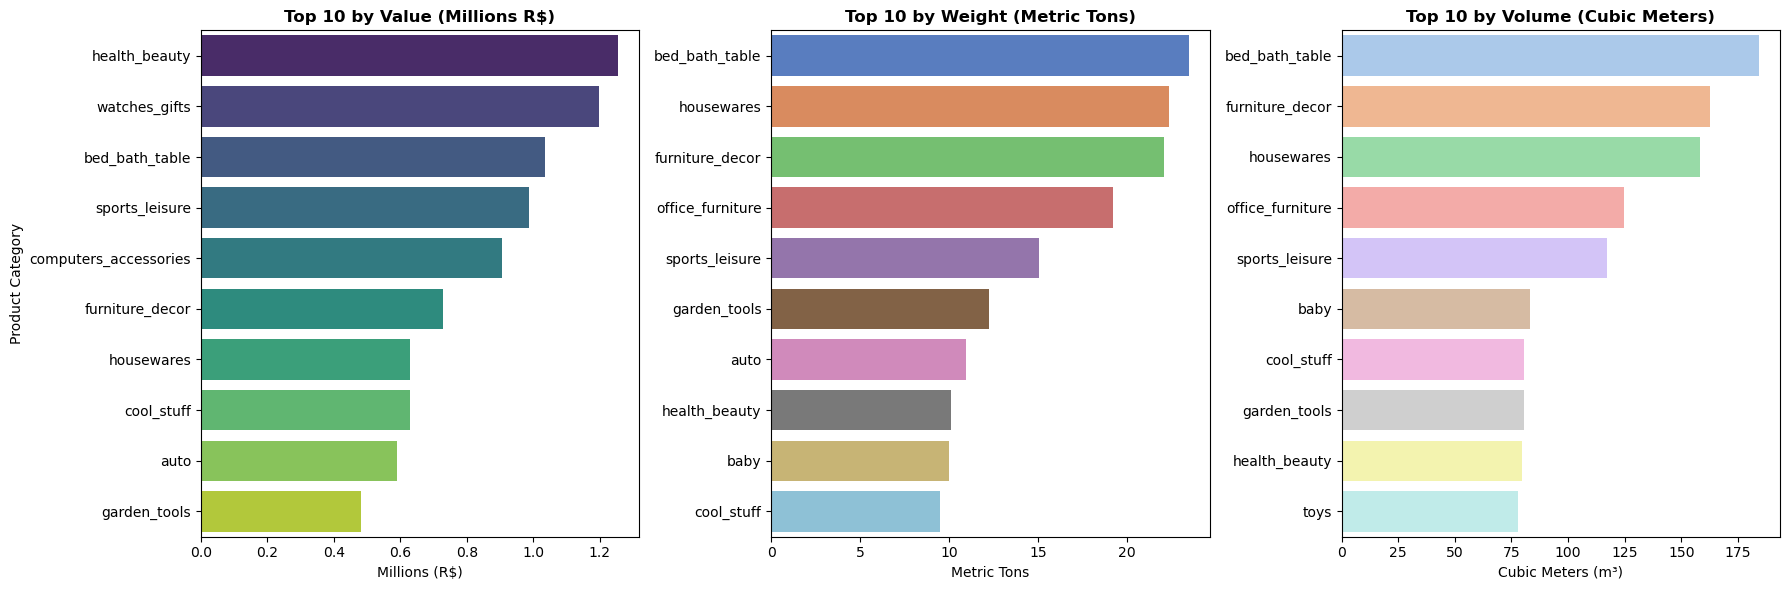

In [50]:
# 3. Build a 3-panel horizontal dashboard to isolate the top drivers
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Panel 1: Top 10 by Financial Value 
top_value = category_metric.sort_values('total_value_millions', ascending=False).head(10)
sns.barplot(
    data=top_value, 
    x='total_value_millions', 
    y='product_category_name', 
    hue='product_category_name', # Added to fix the warning
    legend=False,                # Added to keep the chart clean
    ax=axes[0], 
    palette='viridis'
)
axes[0].set_title('Top 10 by Value (Millions R$)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Millions (R$)')
axes[0].set_ylabel('Product Category')

# Panel 2: Top 10 by Physical Weight
top_weight = category_metric.sort_values('total_weight_tons', ascending=False).head(10)
sns.barplot(
    data=top_weight, 
    x='total_weight_tons', 
    y='product_category_name', 
    hue='product_category_name', # Added to fix the warning
    legend=False,                # Added to keep the chart clean
    ax=axes[1], 
    palette='muted'
)
axes[1].set_title('Top 10 by Weight (Metric Tons)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Metric Tons')
axes[1].set_ylabel('')

# Panel 3: Top 10 by Physical Volume 
top_volume = category_metric.sort_values('total_volume_m3', ascending=False).head(10)
sns.barplot(
    data=top_volume, 
    x='total_volume_m3', 
    y='product_category_name', 
    hue='product_category_name', # Added to fix the warning
    legend=False,                # Added to keep the chart clean
    ax=axes[2], 
    palette='pastel'
)
axes[2].set_title('Top 10 by Volume (Cubic Meters)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Cubic Meters (m³)')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

In [51]:
# 1. Count the physical items supplied per category by each seller city
city_supply = dfm.groupby(['product_category_name', 'seller_city']).size().reset_index(name='items_supplied')

# 2. Calculate the total national volume for each category
city_supply['national_category_total'] = city_supply.groupby('product_category_name')['items_supplied'].transform('sum')

# 3. Calculate the city's monopoly power (Market Share %) for that category
city_supply['market_share_pct'] = (city_supply['items_supplied'] / city_supply['national_category_total']) * 100

# 4. Isolate the Industrial Hubs: Cities controlling > 25% of a category (minimum 500 items to filter out noise)
industrial_clusters = city_supply[
    (city_supply['market_share_pct'] > 25) & 
    (city_supply['items_supplied'] > 500)
].sort_values('market_share_pct', ascending=False)

# Display the supply monopolies
display(industrial_clusters.head(15))

,product_category_name,seller_city,items_supplied,national_category_total,market_share_pct
2468,office_furniture,itaquaquecetuba,1373,1685,81.483680
3114,telephony,sao paulo,2923,4515,64.739756
419,bed_bath_table,ibitinga,6017,11086,54.275663
953,cool_stuff,sao paulo,1927,3749,51.400373
1120,electronics,sao paulo,1321,2674,49.401645
1187,fashion_bags_accessories,sao paulo,998,2023,49.332674
1620,garden_tools,sao jose do rio preto,1879,4335,43.344867
1468,furniture_decor,sao paulo,2906,8312,34.961501
2984,stationery,campo limpo paulista,832,2499,33.293317
3220,toys,sao paulo,1283,4081,31.438373


## Phase 6: Exploratory Data Analysis (EDA) - Supply-Side Industrial Clusters

While customer demand is highly fragmented across 4,060 cities, the supply side of the network exhibits extreme industrial clustering. By analyzing category market share by origin city, we can identify specialized manufacturing and distribution monopolies.

**Key Network Discoveries:**
1. **The Furniture Hub (Itaquaquecetuba):** Controls 81.5% of the national office furniture supply. Due to the high-volume, "cube-out" nature of furniture, this origin point requires dedicated, high-capacity linehaul routing.
2. **The Textile Hub (Ibitinga):** Controls 54.3% of the bed, bath, and table category, acting as the primary anchor for daily household freight.
3. **The High-Value Tech Hub (São Paulo):** Dominates high-value, low-weight categories like telephony (64.7%) and electronics (49.4%), dictating the origin point for high-security, dense-payload freight.

Identifying these industrial monopolies ensures that when we generate our Plant Nodes in the ML phase, we account for specialized regional freight profiles rather than treating all supply origins as homogenous.

## Phase 6: Machine Learning - Geographic Supply Consolidation 

**Why this Exercise? (The Optimization Constraint)**
The Olist network contains 611 distinct seller cities. If we pass 611 origin points and 50 destination hubs into a Mixed-Integer Linear Programming (MILP) solver, the routing permutations multiply exponentially, exceeding standard computational limits and crashing the solver. 

To make the mathematics solvable, we must consolidate the supply side. We will cluster the 611 micro-locations into a smaller, highly concentrated set of macro **Plant Nodes** (industrial supply hubs). This compresses the network matrix while preserving the physical origin points of the freight.

**Why DBSCAN instead of K-Means?**
In physical supply chain engineering, forcing geographic coordinates into an algorithm like K-Means creates operational flaws. We are using **Density-Based Spatial Clustering of Applications with Noise (DBSCAN)** for three specific logistics reasons:

1. **Natural Industrial Hubs, Not Forced Circles:** K-Means forces clusters into rigid, spherical shapes and requires guessing the exact number of hubs ($k$). DBSCAN organically traces the continuous physical density of actual manufacturing zones (like the São Paulo industrial corridor), adjusting to their true geographic shape.
2. **Isolating Remote Freight (Noise):** Supply chains always have remote, isolated sellers. K-Means will ruin a cluster's center of gravity by stretching it to include a remote seller hundreds of kilometers away. DBSCAN correctly flags these isolated sellers as "Noise" (Cluster -1), allowing us to handle them as direct-ship routing exceptions rather than letting them distort our core linehaul hubs.
3. **Data Space vs. Feature Space:** Because DBSCAN relies strictly on spatial density ($Epsilon$ distance), feeding it pure coordinate data ensures our clusters are bound by physical driving distance, preventing the algorithm from grouping distant cities together just because they share similar freight volumes.

In [52]:
# 1. Isolate the unique seller locations to map the physical supply network
seller_locations = dfm[['seller_city', 'seller_lat', 'seller_lng']].drop_duplicates().reset_index(drop=True)

# 2. Extract just the numerical coordinates as a 2D NumPy array for the ML algorithm
seller_coords = seller_locations[['seller_lat', 'seller_lng']].values

# Verify the shape of our spatial matrix
print(f"Unique physical locations to cluster: {seller_coords.shape}")

Unique physical locations to cluster: (2273, 2)


In [53]:
# This works perfectly on NumPy arrays
seller_coords[:5]


array([[-23.68072925, -46.44423827],
       [-19.80768066, -43.98042684],
       [-21.36350171, -48.22960078],
       [-19.83768156, -43.92405254],
       [-23.5433946 , -46.26208568]])

In [54]:
import numpy as np
from sklearn.cluster import DBSCAN

# 1. Drop the duplicate columns created during earlier merges
seller_locations = seller_locations.loc[:, ~seller_locations.columns.duplicated()].copy()

# 2. Extract strictly the 2 columns we need
coords_2d = seller_locations[['seller_lat', 'seller_lng']].values

# 3. Convert to radians
coords_radians = np.radians(coords_2d)

# Failsafe check: This will now print exactly (2273, 2)
print(f"Cleaned algorithm input shape: {coords_radians.shape}")

# 4. Set the 50km radius parameters
kms_per_radian = 6371.0088 
epsilon = 50 / kms_per_radian 

# 5. Run DBSCAN
dbscan = DBSCAN(eps=epsilon, min_samples=5, algorithm='ball_tree', metric='haversine')
seller_locations['cluster_id'] = dbscan.fit_predict(coords_radians)

# 6. Show the results
cluster_counts = seller_locations['cluster_id'].value_counts()
print("\nNumber of sellers assigned to each Plant Node (Top 5 clusters):")
print(cluster_counts.head())
print(f"\nRemote sellers classified as 'Noise' (Cluster -1): {cluster_counts.get(-1, 0)}")

Cleaned algorithm input shape: (2273, 2)

Number of sellers assigned to each Plant Node (Top 5 clusters):
cluster_id
 0    1525
-1     151
 4     125
 6     107
 1      90
Name: count, dtype: int64

Remote sellers classified as 'Noise' (Cluster -1): 151


In [ ]:
df1=dfm.copy()

In [55]:
# 1. Strip the duplicate coordinate columns out of the master dataframe
dfm = dfm.loc[:, ~dfm.columns.duplicated()].copy()

# 2. Map the Plant Node IDs back to the master logistics dataframe
dfm = dfm.merge(
    seller_locations[['seller_city', 'seller_lat', 'seller_lng', 'cluster_id']],
    on=['seller_city', 'seller_lat', 'seller_lng'],
    how='left'
)

# 3. Rename the column to logistics terminology
dfm.rename(columns={'cluster_id': 'plant_node_id'}, inplace=True)

# 4. Calculate the actual physical volume (package count) originating from each Plant Node
node_volume = dfm['plant_node_id'].value_counts()

print("Total packages originating from each Plant Node (Top 5):")
print(node_volume.head())
print(f"\nTotal packages treated as remote exception freight (Noise -1): {node_volume.get(-1.0, 0)}")

Total packages originating from each Plant Node (Top 5):
plant_node_id
 0    88673
-1     4428
 1     4039
 6     3692
 4     3608
Name: count, dtype: int64

Total packages treated as remote exception freight (Noise -1): 4428


In [60]:
# 1. Ensure the volume column exists in memory (calculated from cm to m3)
dfm['volume_m3'] = (dfm['product_length_cm'] * dfm['product_height_cm'] * dfm['product_width_cm']) / 1_000_000

# 2. Aggregate the physical payload constraints for the MILP solver
node_constraints = dfm.groupby('plant_node_id').agg(
    total_packages=('order_id', 'count'),
    total_payload_tons=('product_weight_g', lambda x: x.sum() / 1_000_000), # Convert grams to Metric Tons
    total_cube_m3=('volume_m3', 'sum') # <-- Updated to match the column name above!
).reset_index()

# 3. Sort by payload weight to see where the heaviest freight originates
node_constraints = node_constraints.sort_values('total_payload_tons', ascending=False)
node_constraints.head()

,plant_node_id,total_packages,total_payload_tons,total_cube_m3
1,0,88673,181.138823,1372.426070
0,-1,4428,12.147814,57.754220
7,6,3692,9.088148,61.877038
5,4,3608,7.980775,56.386544
2,1,4039,6.505222,48.664093


In [61]:
print(f"Total unique Plant Nodes (including -1 Noise): {dfm['plant_node_id'].nunique()}")

Total unique Plant Nodes (including -1 Noise): 22


## Supply Chain Optimization: MILP Model Assumptions & Fleet Constraints

To accurately model the consolidation of Brazilian e-commerce freight, this optimization engine operates under a strictly defined set of physical and financial constraints. Below are the core assumptions governing the Mixed-Integer Linear Programming (MILP) solver.

### 1. Fleet Vehicle Types & Capacities
The routing solver selects from three distinct vehicle classes, balancing payload capacity against base trip costs to find the absolute minimum total expenditure per Plant Node.

* **Light Duty (VUC - Veículo Urbano)**
  * **Capacity:** 2.0 Metric Tons | 15.0 m³
  * **Base Trip Cost:** R$ 450
  * **Best For:** Small exception freight and tight urban routing.
* **Medium Duty (Toco - 2-Axle Truck)**
  * **Capacity:** 6.0 Metric Tons | 35.0 m³
  * **Base Trip Cost:** R$ 1,050
  * **Best For:** Standard pallets and regional hub transfers.
* **Heavy Duty (Carreta - Articulated)**
  * **Capacity:** 25.0 Metric Tons | 95.0 m³
  * **Base Trip Cost:** R$ 3,200
  * **Best For:** Massive linehaul consolidation (e.g., the São Paulo mega-hub).

### 2. Core Mathematical Assumptions
* **Strict Demand Clearance:** The solver is mathematically constrained to fulfill 100% of the freight volume and weight at every consolidation hub. No cargo can be left at the origin to artificially lower transportation costs.
* **Dual-Constraint Capacity:** A vehicle is classified as "full" the moment it hits *either* its weight limit (Tons) or its spatial limit (Cubic Meters). For example, a Carreta loaded with 95 m³ of lightweight textiles will depart even if its physical weight is only 5 tons.
* **Integer-Only Dispatching:** Vehicles can only be hired in whole, discrete units. The model assumes partial truckloads (LTL) are billed at the full truckload (FTL) base rate, forcing the optimization engine to maximize freight consolidation.
* **Static Fare Pricing:** Transportation base costs are fixed per vehicle class, assuming negotiated annual carrier rates. The model does not account for dynamic spot market pricing, seasonal rate spikes, or fuel surcharges.

In [62]:
import pulp

def optimize_fleet(payload_tons, cube_m3):
    # 1. Initialize the MILP Model
    model = pulp.LpProblem("Minimize_Transportation_Cost", pulp.LpMinimize)
    
    # 2. Define Variables (PuLP 4.0+ syntax: attached directly to the model)
    V = model.add_variable("VUC_Light", lowBound=0, cat='Integer')
    T = model.add_variable("Toco_Medium", lowBound=0, cat='Integer')
    C = model.add_variable("Carreta_Heavy", lowBound=0, cat='Integer')
    
    # 3. The Objective Function (Minimize Cost)
    model += 450 * V + 1050 * T + 3200 * C, "Total_Cost"
    
    # 4. The Physical Constraints
    model += (2.0 * V) + (6.0 * T) + (25.0 * C) >= payload_tons, "Weight_Constraint"
    model += (15.0 * V) + (35.0 * T) + (95.0 * C) >= cube_m3, "Volume_Constraint"
    
    # 5. Solve the model using the automatic default solver
    model.solve()
    
    # Return the optimal number of trucks and the final lowest cost
    return pulp.value(V), pulp.value(T), pulp.value(C), pulp.value(model.objective)

# Test it on Node 4 (8 Tons, 57 m3)
v_count, t_count, c_count, total_cost = optimize_fleet(8, 57)

print("Optimal Fleet Dispatch for Node 4:")
print(f"VUC (Light): {v_count}")
print(f"Toco (Medium): {t_count}")
print(f"Carreta (Heavy): {c_count}")
print(f"Total Minimum Cost: R$ {total_cost}")

Welcome to the CBC MILP Solver
Version: Devel (unstable)
Build Date: Mar 23 2026
command line - C:\Users\HP\AppData\Local\Temp\3a09b626703348498fb56c8d059f46c5-pulp.mps -timeMode elapsed -solve -printingOptions all -solution C:\Users\HP\AppData\Local\Temp\3a09b626703348498fb56c8d059f46c5-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 7 COLUMNS
At line 23 RHS
At line 26 BOUNDS
At line 30 ENDATA
Problem MODEL has 2 rows, 3 columns and 6 elements
Coin0008I MODEL read with 0 errors
Continuous objective value is 1710 - 0.006 seconds
Cgl0003I 0 fixed, 3 tightened bounds, 2 strengthened rows, 0 substitutions
Cgl0004I processed model has 2 rows, 3 columns (3 integer (0 of which binary)) and 6 elements
Coin0011I Conflict graph built in 0.001 seconds, density: 0.000%
Cgl0015I Clique Strengthening extended 0 cliques, 0 were dominated
Cbc0045I Nauty did not find any useful orbits in time 0
Cbc0012I Integer solution of 2100 found by DiveCoefficient after 0 iterat

In [64]:
# Group your master dataframe using the correct DBSCAN column name
node_constraints = dfm.groupby('plant_node_id').agg(
    total_payload_tons=('weight_tons', 'sum'),
    total_cube_m3=('volume_m3', 'sum')
).reset_index()

# Sort to see the heaviest hubs first
node_constraints = node_constraints.sort_values('total_payload_tons', ascending=False)
node_constraints.head()

,plant_node_id,total_payload_tons,total_cube_m3
1,0,181.138823,1372.426070
0,-1,12.147814,57.754220
7,6,9.088148,61.877038
5,4,7.980775,56.386544
2,1,6.505222,48.664093


In [66]:
# Create empty lists to store the solver's output for each node
vuc_list = []
toco_list = []
carreta_list = []
cost_list = []

# Assuming your aggregated dataframe is named node_constraints
# (if it's named something else like df_agg, just swap the name here)
for index, row in node_constraints.iterrows():
    # Pass the row's specific freight data into your MILP engine
    v, t, c, cost = optimize_fleet(row['total_payload_tons'], row['total_cube_m3'])
    
    # Store the optimized results
    vuc_list.append(v)
    toco_list.append(t)
    carreta_list.append(c)
    cost_list.append(cost)

# Attach the master dispatch lists to the dataframe
node_constraints['VUC_Count'] = vuc_list
node_constraints['Toco_Count'] = toco_list
node_constraints['Carreta_Count'] = carreta_list
node_constraints['Total_Cost_RS'] = cost_list

# Print the top rows to see the master dispatch plan
node_constraints.head()

Welcome to the CBC MILP Solver
Version: Devel (unstable)
Build Date: Mar 23 2026
command line - C:\Users\HP\AppData\Local\Temp\f7e356b18f6e41fc86545e58a357107f-pulp.mps -timeMode elapsed -solve -printingOptions all -solution C:\Users\HP\AppData\Local\Temp\f7e356b18f6e41fc86545e58a357107f-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 7 COLUMNS
At line 23 RHS
At line 26 BOUNDS
At line 30 ENDATA
Problem MODEL has 2 rows, 3 columns and 6 elements
Coin0008I MODEL read with 0 errors
Continuous objective value is 41172.8 - 0 seconds
Cgl0003I 0 fixed, 3 tightened bounds, 0 strengthened rows, 0 substitutions
Cgl0004I processed model has 2 rows, 3 columns (3 integer (0 of which binary)) and 6 elements
Coin0011I Conflict graph built in 0.006 seconds, density: 0.000%
Cgl0015I Clique Strengthening extended 0 cliques, 0 were dominated
Cbc0045I Nauty did not find any useful orbits in time 0
Cbc0012I Integer solution of 41400 found by DiveCoefficient after 0 iterat

,plant_node_id,total_payload_tons,total_cube_m3,VUC_Count,Toco_Count,Carreta_Count,Total_Cost_RS
1,0,181.138823,1372.426070,87.0,2.0,0.0,41250.0
0,-1,12.147814,57.754220,1.0,2.0,0.0,2550.0
7,6,9.088148,61.877038,2.0,1.0,0.0,1950.0
5,4,7.980775,56.386544,4.0,0.0,0.0,1800.0
2,1,6.505222,48.664093,1.0,1.0,0.0,1500.0


In [67]:
from sklearn.cluster import DBSCAN
import numpy as np

# 1. Isolate the customer coordinates and drop missing values to prevent crashes
customer_coords = dfm[['customer_lat', 'customer_lng']].dropna()

# 2. Convert to radians for the Earth's curvature (Haversine formula)
coords_radians_cust = np.radians(customer_coords)

# 3. Configure DBSCAN for Demand Nodes
# eps: 50km radius (50/6371) to group customers in the same city/region
# min_samples: 50 means we need at least 50 orders in a region to justify a dedicated hub
dbscan_demand = DBSCAN(eps=50/6371.0, min_samples=50, algorithm='ball_tree', metric='haversine')

# 4. Run the clustering engine
customer_coords['demand_node_id'] = dbscan_demand.fit_predict(coords_radians_cust)

# 5. Merge the new Demand Node IDs back into your master dataframe
dfm = dfm.merge(customer_coords['demand_node_id'], left_index=True, right_index=True, how='left')

# 6. Count how many major Destination Hubs the algorithm discovered
# (Subtracting 1 to ignore the -1 noise/outlier label)
total_demand_hubs = len(dfm['demand_node_id'].unique()) - 1

print(f"Total Demand Nodes (Destination Hubs) created: {total_demand_hubs}")

Total Demand Nodes (Destination Hubs) created: 46


## Network Topology: Demand Node (Destination) Clustering

To build a computationally viable Origin-Destination (O-D) Network Flow model, it is impossible to route freight to tens of thousands of individual residential addresses simultaneously. Instead, the model aggregates individual customer locations into centralized regional Delivery Hubs (Demand Nodes) using density-based spatial clustering.

### 1. Spatial Clustering Algorithm (DBSCAN)
The network topology was engineered using **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) applied to the geographical coordinates (latitude/longitude) of the customer base.

* **Distance Metric (Haversine):** The algorithm calculates great-circle distances in radians to account for the Earth's curvature across Brazil's massive landmass.
* **Hub Radius (Epsilon = 50 km):** Customers within a 50-kilometer radius are grouped into a single Demand Node. This reflects a standard, real-world "last-mile" delivery radius for regional distribution centers.
* **Volume Threshold (Min_Samples = 50):** A region must have a historical demand of at least 50 orders to justify the establishment of a dedicated Delivery Hub. 

### 2. Exception Routing (Noise)
Sparse, rural deliveries that do not meet the minimum density threshold (labeled as `-1` by DBSCAN) are excluded from the primary heavy-freight optimization model. In a real-world scenario, these outlier locations would be outsourced to third-party logistics (3PL) partners or the national postal service (Correios) rather than serviced by the internal heavy fleet.

### 3. Final Network Scale
* **Origins:** 22 Plant Nodes (Consolidation Hubs)
* **Destinations:** 46 Demand Nodes (Regional Delivery Hubs)
* **Complexity Reduction:** This clustering reduces the routing problem from millions of potential paths down to a highly tractable matrix of **1,012 potential shipping lanes**, allowing the Mixed-Integer Linear Programming (MILP) engine to solve for global network optimality.

In [68]:
# 1. Filter out the noise (-1) from both origins and destinations
valid_routes = dfm[(dfm['plant_node_id'] != -1) & (dfm['demand_node_id'] != -1)]

# 2. Build the Origin-Destination (O-D) Matrix
od_matrix = valid_routes.groupby(['plant_node_id', 'demand_node_id']).agg(
    total_packages=('order_id', 'count'),
    lane_payload_tons=('weight_tons', 'sum'),
    lane_cube_m3=('volume_m3', 'sum')
).reset_index()

# 3. Sort by heaviest lanes to see our most critical logistics corridors
od_matrix = od_matrix.sort_values('lane_payload_tons', ascending=False)

# 4. Preview the top 5 busiest shipping lanes
od_matrix.head()

,plant_node_id,demand_node_id,total_packages,lane_payload_tons,lane_cube_m3
0,0,0,72880,148.805613,1128.887011
211,6,0,3017,7.491610,51.455179
141,4,0,3107,6.997565,49.071529
46,1,0,3227,5.121382,38.252242
2,0,2,2451,5.003022,37.816082


In [69]:
import numpy as np

# --- 1. Define the Haversine Distance Function ---
def haversine_distance(lat1, lon1, lat2, lon2):
    """Calculates the great-circle distance between two points in kilometers."""
    # Convert latitude and longitude from degrees to radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    
    # Haversine formula
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    r = 6371 # Radius of earth in kilometers
    return c * r

# --- 2. Calculate the Centroids for Origins (Plant Nodes) ---
# Group by Plant Node and calculate the average latitude/longitude
# (Assuming your origin coords are 'seller_lat' and 'seller_lng')
plant_centroids = dfm[dfm['plant_node_id'] != -1].groupby('plant_node_id').agg(
    origin_lat=('seller_lat', 'mean'),
    origin_lng=('seller_lng', 'mean')
).reset_index()

# --- 3. Calculate the Centroids for Destinations (Demand Nodes) ---
# Group by Demand Node and calculate the average latitude/longitude
# (Assuming your destination coords are 'customer_lat' and 'customer_lng')
demand_centroids = dfm[dfm['demand_node_id'] != -1].groupby('demand_node_id').agg(
    dest_lat=('customer_lat', 'mean'),
    dest_lng=('customer_lng', 'mean')
).reset_index()

# --- 4. Merge Coordinates into the O-D Matrix ---
# Add the origin coordinates
od_matrix = od_matrix.merge(plant_centroids, on='plant_node_id', how='left')

# Add the destination coordinates
od_matrix = od_matrix.merge(demand_centroids, on='demand_node_id', how='left')

# --- 5. Calculate the Distance for Every Lane ---
# Apply the Haversine function row-by-row
od_matrix['distance_km'] = od_matrix.apply(
    lambda row: haversine_distance(
        row['origin_lat'], row['origin_lng'], 
        row['dest_lat'], row['dest_lng']
    ), axis=1
)

# Display the O-D Matrix with the new distance column
od_matrix[['plant_node_id', 'demand_node_id', 'lane_payload_tons', 'distance_km']].head()

,plant_node_id,demand_node_id,lane_payload_tons,distance_km
0,0,0,148.805613,73.675655
1,6,0,7.491610,366.145359
2,4,0,6.997565,482.213678
3,1,0,5.121382,455.337391
4,0,2,5.003022,2040.602653


In [70]:
# Create empty lists to store the solver's output for each specific lane
vuc_lane = []
toco_lane = []
carreta_lane = []
cost_lane = []

# Loop through every shipping lane in the network
for index, row in od_matrix.iterrows():
    # Pass the lane's specific freight data into your MILP engine
    v, t, c, cost = optimize_fleet(row['lane_payload_tons'], row['lane_cube_m3'])
    
    # Store the optimized route results
    vuc_lane.append(v)
    toco_lane.append(t)
    carreta_lane.append(c)
    cost_lane.append(cost)

# Attach the master dispatch lists back to the O-D Matrix
od_matrix['VUC_Count'] = vuc_lane
od_matrix['Toco_Count'] = toco_lane
od_matrix['Carreta_Count'] = carreta_lane
od_matrix['Lane_Cost_RS'] = cost_lane

# Preview the fleet dispatch for our heaviest lanes
od_matrix.head()

Welcome to the CBC MILP Solver
Version: Devel (unstable)
Build Date: Mar 23 2026
command line - C:\Users\HP\AppData\Local\Temp\b1207c5be8d84dfdbb339323ab9c27b8-pulp.mps -timeMode elapsed -solve -printingOptions all -solution C:\Users\HP\AppData\Local\Temp\b1207c5be8d84dfdbb339323ab9c27b8-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 7 COLUMNS
At line 23 RHS
At line 26 BOUNDS
At line 30 ENDATA
Problem MODEL has 2 rows, 3 columns and 6 elements
Coin0008I MODEL read with 0 errors
Continuous objective value is 33866.6 - 0 seconds
Cgl0003I 0 fixed, 3 tightened bounds, 0 strengthened rows, 0 substitutions
Cgl0004I processed model has 2 rows, 3 columns (3 integer (0 of which binary)) and 6 elements
Coin0011I Conflict graph built in 0.000 seconds, density: 0.000%
Cgl0015I Clique Strengthening extended 0 cliques, 0 were dominated
Cbc0045I Nauty did not find any useful orbits in time 0
Cbc0012I Integer solution of 33900 found by DiveCoefficient after 0 iterat

,plant_node_id,demand_node_id,total_packages,lane_payload_tons,lane_cube_m3,origin_lat,origin_lng,dest_lat,dest_lng,distance_km,VUC_Count,Toco_Count,Carreta_Count,Lane_Cost_RS
0,0,0,72880,148.805613,1128.887011,-22.922082,-47.155138,-23.296209,-46.560581,73.675655,73.0,1.0,0.0,33900.0
1,6,0,3017,7.491610,51.455179,-25.467402,-49.278897,-23.296209,-46.560581,366.145359,4.0,0.0,0.0,1800.0
2,4,0,3107,6.997565,49.071529,-27.059471,-48.942659,-23.296209,-46.560581,482.213678,1.0,1.0,0.0,1500.0
3,1,0,3227,5.121382,38.252242,-19.899536,-44.100133,-23.296209,-46.560581,455.337391,3.0,0.0,0.0,1350.0
4,0,2,2451,5.003022,37.816082,-22.922082,-47.155138,-8.308502,-35.588796,2040.602653,3.0,0.0,0.0,1350.0


In [71]:
# Calculate the grand totals for the entire Brazilian network
total_vucs = od_matrix['VUC_Count'].sum()
total_tocos = od_matrix['Toco_Count'].sum()
total_carretas = od_matrix['Carreta_Count'].sum()
total_cost_flat = od_matrix['Lane_Cost_RS'].sum()

print("--- 🇧🇷 INITIAL NETWORK BASELINE ---")
print(f"Total VUCs Hired:      {total_vucs}")
print(f"Total Tocos Hired:     {total_tocos}")
print(f"Total Carretas Hired:  {total_carretas}")
print(f"Total Network Cost:    R$ {total_cost_flat:,.2f}")

--- 🇧🇷 INITIAL NETWORK BASELINE ---
Total VUCs Hired:      564.0
Total Tocos Hired:     3.0
Total Carretas Hired:  0.0
Total Network Cost:    R$ 256,950.00


In [72]:
import pulp

def optimize_fleet_dynamic(payload_tons, cube_m3, distance_km):
    # 1. Ensure a minimum billable distance of 50km for local intra-city deliveries
    billable_distance = max(distance_km, 50)
    
    # 2. Dynamic Freight Rates (Base Fixed Cost + Variable R$ per km)
    cost_vuc = 200 + (3.50 * billable_distance)
    cost_toco = 400 + (5.50 * billable_distance)
    cost_carreta = 900 + (8.50 * billable_distance)
    
    # 3. Initialize Model & Variables
    model = pulp.LpProblem("Dynamic_Routing_Cost", pulp.LpMinimize)
    V = model.add_variable("VUC_Light", lowBound=0, cat='Integer')
    T = model.add_variable("Toco_Medium", lowBound=0, cat='Integer')
    C = model.add_variable("Carreta_Heavy", lowBound=0, cat='Integer')
    
    # 4. Objective (Minimize the new dynamic costs)
    model += cost_vuc * V + cost_toco * T + cost_carreta * C, "Total_Cost"
    
    # 5. Physical Constraints
    model += (2.0 * V) + (6.0 * T) + (25.0 * C) >= payload_tons, "Weight_Constraint"
    model += (15.0 * V) + (35.0 * T) + (95.0 * C) >= cube_m3, "Volume_Constraint"
    
    # 6. Solve
    model.solve()
    
    return pulp.value(V), pulp.value(T), pulp.value(C), pulp.value(model.objective)


# Create lists for the dynamic results
dyn_vuc, dyn_toco, dyn_carreta, dyn_cost = [], [], [], []

# Loop through the O-D matrix using the new engine
for index, row in od_matrix.iterrows():
    v, t, c, cost = optimize_fleet_dynamic(
        row['lane_payload_tons'], 
        row['lane_cube_m3'], 
        row['distance_km']
    )
    dyn_vuc.append(v)
    dyn_toco.append(t)
    dyn_carreta.append(c)
    dyn_cost.append(cost)

# Attach the new dynamic baseline to the dataframe
od_matrix['Dyn_VUC'] = dyn_vuc
od_matrix['Dyn_Toco'] = dyn_toco
od_matrix['Dyn_Carreta'] = dyn_carreta
od_matrix['Dyn_Cost_RS'] = dyn_cost

# Print the new national totals
print("--- 🇧🇷 DYNAMIC NETWORK BASELINE ---")
print(f"Total VUCs Hired:      {sum(dyn_vuc)}")
print(f"Total Tocos Hired:     {sum(dyn_toco)}")
print(f"Total Carretas Hired:  {sum(dyn_carreta)}")
print(f"Total Network Cost:    R$ {sum(dyn_cost):,.2f}")

Welcome to the CBC MILP Solver
Version: Devel (unstable)
Build Date: Mar 23 2026
command line - C:\Users\HP\AppData\Local\Temp\6885fd006b294f0eadf88a0f378792b8-pulp.mps -timeMode elapsed -solve -printingOptions all -solution C:\Users\HP\AppData\Local\Temp\6885fd006b294f0eadf88a0f378792b8-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 7 COLUMNS
At line 23 RHS
At line 26 BOUNDS
At line 30 ENDATA
Problem MODEL has 2 rows, 3 columns and 6 elements
Coin0008I MODEL read with 0 errors
Continuous objective value is 18136.4 - 0.002 seconds
Cgl0003I 0 fixed, 3 tightened bounds, 0 strengthened rows, 0 substitutions
Cgl0004I processed model has 2 rows, 3 columns (3 integer (0 of which binary)) and 6 elements
Coin0011I Conflict graph built in 0.000 seconds, density: 0.000%
Cgl0015I Clique Strengthening extended 0 cliques, 0 were dominated
Cbc0045I Nauty did not find any useful orbits in time 0
Cbc0012I Integer solution of 18314.91683123 found by DiveCoefficient a

In [73]:
import folium

# 1. Isolate the top 100 busiest lanes to prevent visual clutter
# (Plotting all 1,000+ lanes would turn the map into a solid block of color)
top_lanes = od_matrix[od_matrix['lane_payload_tons'] > 0].head(100)
max_payload = top_lanes['lane_payload_tons'].max()

# 2. Initialize an interactive map centered on Brazil with a dark theme
brazil_map = folium.Map(
    location=[-15.7801, -47.9292], 
    zoom_start=4, 
    tiles='cartodbdark_matter' # Dark background for high contrast
)

# 3. Loop through the heaviest lanes and map them
for index, row in top_lanes.iterrows():
    origin = [row['origin_lat'], row['origin_lng']]
    dest = [row['dest_lat'], row['dest_lng']]
    
    # Scale line thickness mathematically (max thickness = 8 pixels)
    line_weight = (row['lane_payload_tons'] / max_payload) * 8
    
    # Draw the shipping lane (PolyLine)
    folium.PolyLine(
        locations=[origin, dest],
        weight=max(1, line_weight), # Ensure even small lanes are at least 1px visible
        color='#00FFCC', # High-contrast cyan
        opacity=0.5,
        tooltip=(f"Origin Node: {row['plant_node_id']} &rarr; Dest Node: {row['demand_node_id']}<br>"
                 f"Payload: {row['lane_payload_tons']:.2f} Tons<br>"
                 f"Est. Freight Cost: R$ {row['Dyn_Cost_RS']:,.2f}")
    ).add_to(brazil_map)

    # Add a glowing yellow dot for the Origin Hub
    folium.CircleMarker(
        location=origin,
        radius=3,
        color='#FFD700',
        fill=True,
        fill_opacity=1
    ).add_to(brazil_map)

# 4. Render the interactive map directly in the notebook
brazil_map

In [1]:
# 1. Install geopy if you do not have it (uncomment the line below to install)
# !pip install geopy

import pandas as pd
from geopy.geocoders import Nominatim
import time

# 2. Load your existing dataset
df = pd.read_csv('Optimized_Shipping_Lanes.csv')

# 3. Set up the Geocoder
geolocator = Nominatim(user_agent="supply_chain_portfolio")

def get_brazil_city(lat, lon):
    try:
        location = geolocator.reverse((lat, lon), timeout=10, language='en')
        address = location.raw.get('address', {})
        # Extract the most accurate city/town name
        city = address.get('city', address.get('town', address.get('village', address.get('municipality', 'Unknown'))))
        state = address.get('state', '')
        return f"{city}, {state}"
    except:
        return f"Node ({lat:.1f}, {lon:.1f})"

# 4. Map Origins (Seller Hubs)
print("Mapping Seller Hubs to Cities...")
unique_origins = df[['plant_node_id', 'origin_lat', 'origin_lng']].drop_duplicates()
origin_dict = {}
for _, row in unique_origins.iterrows():
    origin_dict[row['plant_node_id']] = get_brazil_city(row['origin_lat'], row['origin_lng'])
    time.sleep(1) # Required 1-second pause to prevent API rate limits

# 5. Map Destinations (Customer Regions)
print("Mapping Customer Regions to Cities...")
unique_dests = df[['demand_node_id', 'dest_lat', 'dest_lng']].drop_duplicates()
dest_dict = {}
for _, row in unique_dests.iterrows():
    dest_dict[row['demand_node_id']] = get_brazil_city(row['dest_lat'], row['dest_lng'])
    time.sleep(1)

# 6. Apply the real names as brand new columns
df['Origin_City'] = df['plant_node_id'].map(origin_dict)
df['Dest_City'] = df['demand_node_id'].map(dest_dict)

# 7. Save and overwrite the CSV
df.to_csv('Optimized_Shipping_Lanes.csv', index=False)
print("Done! CSV successfully updated with real city names.")

Mapping Seller Hubs to Cities...
Mapping Customer Regions to Cities...
Done! CSV successfully updated with real city names.
